# Exploratory Data Analysis — Class, Subject & Date Distributions

Structural EDA on the raw ISOT datasets (`True.csv`, `Fake.csv`): class
balance, subject categories, and the publication timeline.
Distributions and charts only — no preprocessing, feature engineering, or modeling.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Resolve the raw data directory
candidates = (Path("../data/raw"), Path("backend/ml/data/raw"))
data_dir = next((p for p in candidates if p.is_dir()), None)
if data_dir is None:
    raise FileNotFoundError(f"Could not locate backend/ml/data/raw/ from {Path.cwd()}")

true_path = data_dir / "True.csv"
fake_path = data_dir / "Fake.csv"
for path in (true_path, fake_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing dataset: {path.resolve()}")

print(f"Using raw data directory: {data_dir}")

Using raw data directory: ..\data\raw


## Load and label the data

Label encoding: real = 1 (`True.csv`), fake = 0 (`Fake.csv`), then merge
and shuffle into a single frame for analysis.

In [3]:
true_df = pd.read_csv(true_path)
fake_df = pd.read_csv(fake_path)

true_df["label"] = 1  # real
fake_df["label"] = 0  # fake

df = pd.concat([true_df, fake_df], ignore_index=True).sample(frac=1, random_state=42)
df["class"] = df["label"].map({1: "True", 0: "Fake"})

df.head()

,title,text,subject,date,label,class
22216,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0,Fake
27917,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0,Fake
25007,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0,Fake
1377,California AG pledges to defend birth control ...,SAN FRANCISCO (Reuters) - California Attorney ...,politicsNews,"October 6, 2017",1,True
32476,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,politics,"Apr 25, 2017",0,Fake


## Class distribution

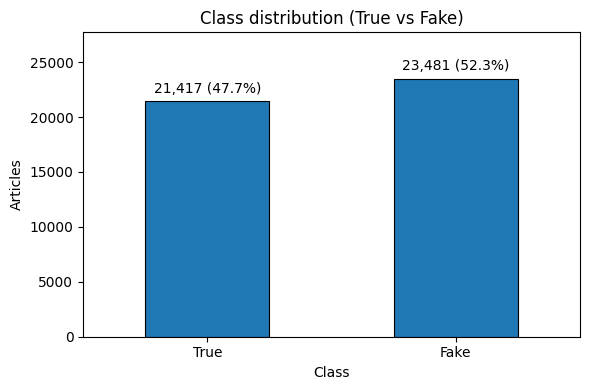

In [4]:
counts = df["class"].value_counts().reindex(["True", "Fake"])

ax = counts.plot(kind="bar", rot=0, figsize=(6, 4), edgecolor="black", linewidth=0.8)
ax.set_ylim(0, counts.max() * 1.18)
ax.bar_label(ax.containers[0], labels=[f"{v:,} ({v / len(df):.1%})" for v in counts], padding=4)
ax.set_title("Class distribution (True vs Fake)")
ax.set_xlabel("Class")
ax.set_ylabel("Articles")
plt.tight_layout()

**Observations**

- The two classes are nearly balanced: 21,417 True (47.7%) vs 23,481 Fake
  (52.3%) out of 44,898 total articles.
- No class dominates the dataset.

## Subject distribution

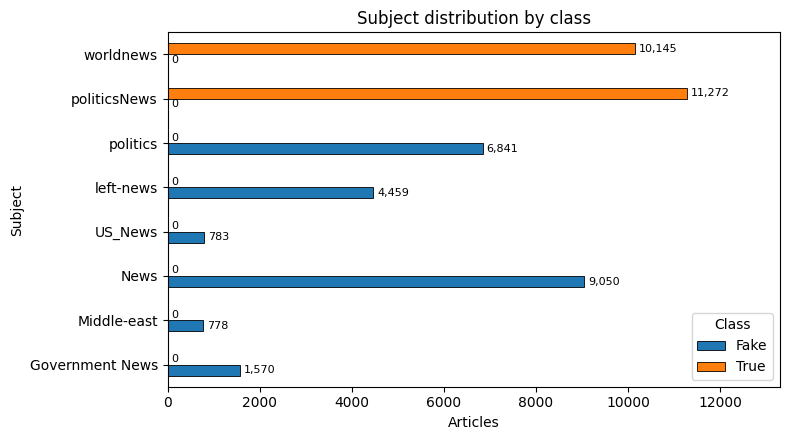

In [5]:
subject_by_class = pd.crosstab(df["subject"], df["class"])

ax = subject_by_class.plot(kind="barh", figsize=(8, 4.5), edgecolor="black", linewidth=0.6)
ax.set_xlim(0, subject_by_class.to_numpy().max() * 1.18)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v):,}" for v in container.datavalues], padding=3, fontsize=8)
ax.set_title("Subject distribution by class")
ax.set_xlabel("Articles")
ax.set_ylabel("Subject")
ax.legend(title="Class")
plt.tight_layout()

**Observations**

- The subject sets are completely disjoint. True contains only `politicsNews`
  (11,272) and `worldnews` (10,145); Fake uses six other subjects, led by
  `News` (9,050), `politics` (6,841) and `left-news` (4,459).
- Because no subject is shared between classes, `subject` predicts the class
  perfectly on this dataset — strong signal, but it reflects source metadata
  rather than article content.

## Publication date distribution

In [6]:
df["published"] = pd.to_datetime(df["date"], errors="coerce", format="mixed")

unparsed = df["published"].isna().sum()
print(f"Parsed {len(df) - unparsed:,} / {len(df):,} dates ({unparsed} malformed, all Fake)")
df["published"].agg(["min", "max"])

Parsed 44,888 / 44,898 dates (10 malformed, all Fake)


min   2015-03-31
max   2018-02-19
Name: published, dtype: datetime64[ns]

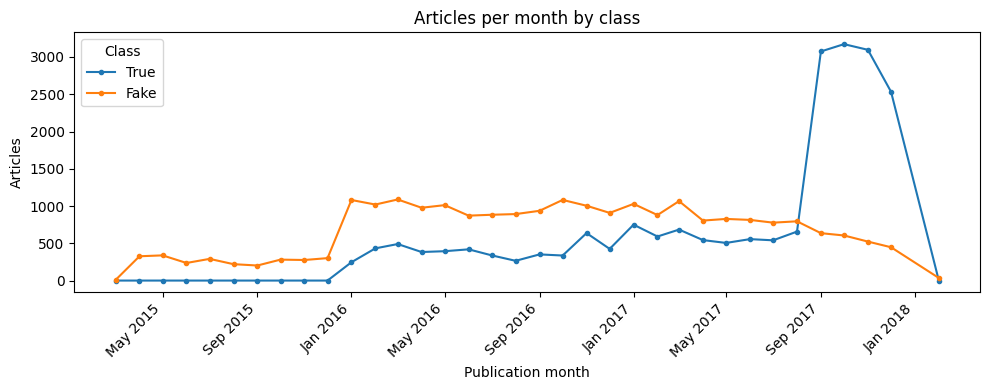

In [7]:
valid = df.dropna(subset=["published"])
monthly = (
    valid.groupby([valid["published"].dt.to_period("M"), "class"])
    .size()
    .unstack("class")
    .reindex(columns=["True", "Fake"])
    .fillna(0)
)
monthly.index = monthly.index.to_timestamp()  # period -> first day of month

ax = monthly.plot(figsize=(10, 4), marker=".", linewidth=1.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Articles per month by class")
ax.set_xlabel("Publication month")
ax.set_ylabel("Articles")
ax.legend(title="Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

**Observations**

- Publication dates span 2015-03-31 → 2018-02-19. Ten Fake rows contain
  malformed values (URLs or headlines in the `date` column) and are excluded
  from the timeline: 44,888 of 44,898 articles are plottable.
- True articles appear only in 2016–2017 and are heavily concentrated in
  Sep–Dec 2017 (peak Oct 2017, 3,172 articles); Fake covers the whole
  2015–2018 range (peak Mar 2016, 1,088) and is the only class present in
  2015 and 2018.
- The classes therefore come from partially different time periods, so
  publication date is confounded with the label.